# Exercise - Simple Linear Regression



In this notebook you can check your understanding of linear regression and implement a linear regression model with scikit-learn by yourself. 




## Learning Objectives

At the end of this notebook, you should be able to: 
- Describe the relationship between two variables.
- Train a linear regression model with scikit-learn.
- Interpret the $R^2$ of a linear regression model.

## Question 1 



The scatter plots below show the relationship between height, diameter, and volume of timber in 31 felled black cherry trees. The diameter of the tree is measured 4.5 feet above the ground.  

<img src="assets/lin_reg_ex_1.png" width="600">  

**(a) Describe the relationship between volume and height of these trees.**

**Answer (a):** Positive but **weak**. Taller trees tend to hold more wood, but the points are widely scattered. Trees of about 80 ft range from roughly 20 to 58 cubic ft. The spread also grows as height grows. The trend looks roughly linear, with no clear curve.

**(b) Describe the relationship between volume and diameter of these trees.**

**Answer (b):** Positive and **strong**. The points sit close to a rising line: thicker trees clearly hold more wood. There is a slight upward bend (volume grows a bit faster for the thickest trees, because the cross-section area grows with diameter squared). The thickest tree (about 20.6 in, about 77 cubic ft) sits at the top right and still follows the trend.

**(c) Suppose you measured the height and diameter of another black cherry tree. Which of these variables would be better for predicting the wood volume of this tree using a simple linear regression model? Explain your reasoning.**

**Answer (c):** **Diameter.** Its points lie much closer to a straight line, so a line through them leaves small errors (residuals) and would get a much higher $R^2$. Height leaves a lot of the volume unexplained: two trees of the same height can differ in volume by a factor of 2 to 3.

## Question 2 

The file `utils.csv` in your data folder contains information about the average utility bills for homes of a particular size and the average monthly temperature.  

**(a) Load the data:**

In [1]:
# Tools we need for this exercise
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [2]:
# Load the table: one row per month (12 rows, 3 columns)
utils = pd.read_csv("data/utils.csv")
utils

,Month,Average Bill,Average Monthly Temperature
0,Jan,148.5,38
1,Feb,136.5,45
2,Mar,117.0,49
3,Apr,91.5,57
4,May,82.5,69
5,Jun,94.5,78
6,Jul,120.0,84
7,Aug,142.5,89
8,Sep,97.5,79
9,Oct,84.0,64


**(b) Make a scatter plot of the data average bill vs average monthly temperature. Which variable would make the most sense as the response variable?**

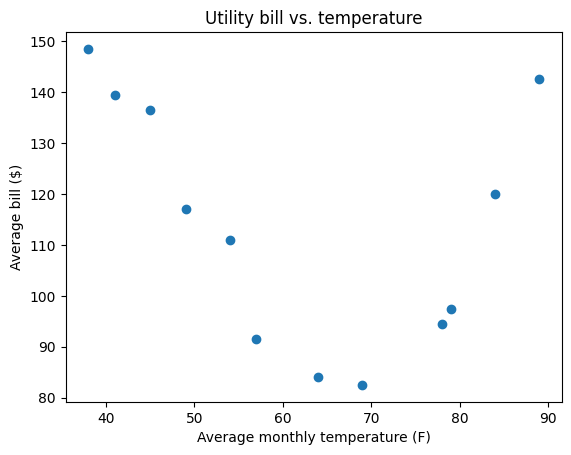

In [3]:
# Temperature on the x-axis (the cause), bill on the y-axis (the effect)
plt.scatter(utils["Average Monthly Temperature"], utils["Average Bill"])
plt.xlabel("Average monthly temperature (F)")
plt.ylabel("Average bill ($)")
plt.title("Utility bill vs. temperature");

**Answer (b):** The **average bill** is the response (target) variable. The weather drives the bill (heating and cooling), not the other way round, so temperature is the explanatory variable (feature).

**(c) Have a look at the plot above. How would you describe the relationship between the variables?** 

**Answer (c):** The relationship is **not linear, it is U-shaped (curved)**. Bills are highest in the coldest months (January: \$148.50 at 38 F, heating) and rise again in the hottest months (August: \$142.50 at 89 F, air conditioning). They are lowest in mild months (May: \$82.50 at 69 F). A straight line cannot follow this shape.

**(d) Train a simple linear regression model using scikit-learn**

In [4]:
# Feature X needs double brackets (a table), target y single (a column)
X = utils[["Average Monthly Temperature"]]
y = utils["Average Bill"]

# Create the model and fit the straight line to the 12 months
lin_reg = LinearRegression()
lin_reg.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.48]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Average Monthly Temperature']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,143.6
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


**(e) Calculate and interpret the value of $R^2$.**  

In [5]:
# Predicted bills for the 12 months, then compare with the real bills
y_hat = lin_reg.predict(X)
print("R-squared:", round(r2_score(y, y_hat), 3))

R-squared: 0.124


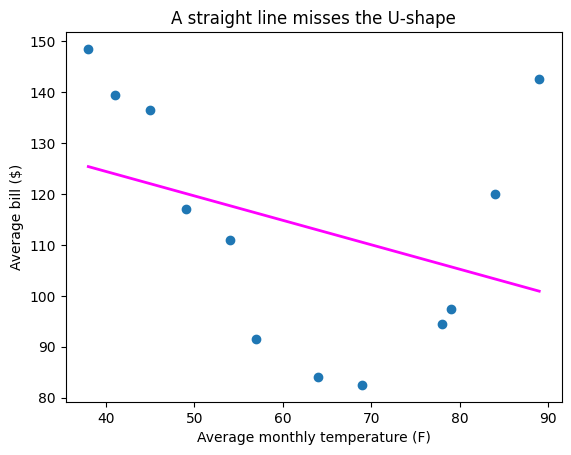

In [6]:
# Draw the fitted line on top of the data to see why R-squared is low
plt.scatter(X, y)
order = X["Average Monthly Temperature"].argsort()
plt.plot(X.iloc[order], y_hat[order], color="magenta", linewidth=2)
plt.xlabel("Average monthly temperature (F)")
plt.ylabel("Average bill ($)")
plt.title("A straight line misses the U-shape");

**Answer (e):** $R^2 = 0.124$. The straight line explains only **12.4 %** of the month-to-month variation in the bill. This does not mean temperature is unimportant: the bill clearly depends on it. It means a *straight line* is the wrong shape for this U-shaped relationship (see the plot above).

**(f) Print the intercept and slope/coefficient and interpret them in terms a home owner would understand.**

In [7]:
# Intercept = bill at 0 F; slope = change in bill per +1 F
print("Intercept:", round(lin_reg.intercept_, 2))
print("Slope:", round(lin_reg.coef_[0], 3))

Intercept: 143.62
Slope: -0.48


**Answer (f), in home-owner words:**
- **Intercept \$143.62:** the model's bill for a month averaging 0 F. No month in the data is that cold (the range is 38 to 89 F), so this is just where the line starts, not a real forecast.
- **Slope -0.48:** for every 1 F warmer month, the model expects the bill to be about **48 cents lower**; 10 F warmer means about \$4.80 less. This is only an average tilt over the whole year. In summer, bills really go *up* with the heat, which the line misses.

**(g) Use your fitted model to estimate the average utility bill if the average monthly temperature is 120 degrees Fahrenheit. Do you think that your answer is reasonable? Why or why not?** 

In [8]:
# A month with an average of 120 F (far hotter than any month in the data)
hot_month = pd.DataFrame({"Average Monthly Temperature": [120]})
print("Predicted bill at 120 F:", lin_reg.predict(hot_month)[0].round(2))
print("Temperature range in the data:",
      X["Average Monthly Temperature"].min(), "to",
      X["Average Monthly Temperature"].max(), "F")

Predicted bill at 120 F: 86.04
Temperature range in the data: 38 to 89 F


**Answer (g):** The model predicts **\$86.04** for a 120 F month. That is **not reasonable**:
1. **Extrapolation:** 120 F is far outside the temperatures the model has seen (38 to 89 F). A model only knows the range it was trained on.
2. **Wrong direction:** the data show bills rising in hot months (air conditioning). A 120 F month would most likely produce one of the *highest* bills, but the straight line keeps going down and predicts one of the lowest.